# Détection d'oiseaux ravageurs du riz – Vallée du fleuve Sénégal
Classification binaire **ravageur potentiel / non prioritaire** (CUB-200-2011 sous-échantillonné).
Pipeline : données → baseline CNN → MobileNetV2 (transfert learning + fine-tuning) → évaluation (recall prioritaire) → analyse d'erreurs → démo Gradio.
> Exécuter avec GPU : *Exécution > Modifier le type d'exécution > T4 GPU*.

In [1]:
!pip install -q datasets gradio scikit-learn seaborn

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time, json, tensorflow as tf
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_curve,
                             precision_score, recall_score, f1_score, roc_auc_score)
from tensorflow.keras import layers, models
SEED, IMG = 42, 224
tf.keras.utils.set_random_seed(SEED)
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Chargement et exploration

In [3]:
dataset = load_dataset("Donghyun99/CUB-200-2011")
class_names = dataset["train"].features["label"].names
print(dataset, len(class_names), "classes")

README.md:   0%|          | 0.00/7.40k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  286MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  296MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

...

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  285MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5994 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5794 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 5994
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 5794
    })
}) 200 classes


## 2. Choix des classes « ravageur potentiel »
CUB-200 ne contient pas les Queleas ni les Dendrocygnes. On utilise donc des **proxys** : petits granivores (carouges, bruants, pinsons, chardonnerets, grosbecs, bobolink) qui se nourrissent de graines/céréales comme les Queleas. C'est une limite à documenter : le modèle apprend « petit passereau granivore », pas la vraie espèce locale.

In [6]:
# 1. Sélection des identifiants des espèces considérées comme « ravageurs »
RAVAGEUR_IDS = [8,9,10,11,12,13,14,15,16,33,34,46,47,53,56]
print("Espèces cibles sélectionnées :", [class_names[i] for i in RAVAGEUR_IDS])

# 2. Fonction pour convertir les images du dataset en tenseurs NumPy standardisés
def to_arrays(split):
    X = np.zeros((len(split), IMG, IMG, 3), dtype=np.uint8)
    for i, ex in enumerate(split):
        # Chargement, conversion en RGB (gestion du niveaux de gris) et redimensionnement
        X[i] = np.asarray(ex["image"].convert("RGB").resize((IMG, IMG)))
    return X, np.array(split["label"])

# Extraction des caractéristiques (images) et étiquettes d'origine
X_all, lab_all = to_arrays(dataset["train"])
X_te, lab_te = to_arrays(dataset["test"])

# 3. Création des étiquettes binaires : 1.0 si l'espèce est un ravageur, 0.0 sinon
y_all = np.isin(lab_all, RAVAGEUR_IDS).astype("float32")
y_te  = np.isin(lab_te,  RAVAGEUR_IDS).astype("float32")

# 4. Partitionnement stratifié (80% Train, 20% Validation) pour conserver le ratio de la classe minoritaire
idx_tr, idx_val = train_test_split(np.arange(len(y_all)), test_size=0.2, stratify=y_all, random_state=SEED)

# Extraction finale des ensembles d'entraînement et de validation
X_tr, y_tr, lab_tr = X_all[idx_tr], y_all[idx_tr], lab_all[idx_tr]
X_val, y_val = X_all[idx_val], y_all[idx_val]

# Affichage des dimensions et du taux de déséquilibre des classes
for n, y in [("train", y_tr), ("val", y_val), ("test", y_te)]:
    print(f"{n:6} n={len(y):5}  ravageur={y.mean():.1%}")

Espèces cibles sélectionnées : ['Brewer_Blackbird', 'Red_winged_Blackbird', 'Rusty_Blackbird', 'Yellow_headed_Blackbird', 'Bobolink', 'Indigo_Bunting', 'Lazuli_Bunting', 'Painted_Bunting', 'Cardinal', 'Gray_crowned_Rosy_Finch', 'Purple_Finch', 'American_Goldfinch', 'European_Goldfinch', 'Blue_Grosbeak', 'Rose_breasted_Grosbeak']
train  n= 4795  ravageur=7.5%
val    n= 1199  ravageur=7.5%
test   n= 5794  ravageur=7.5%


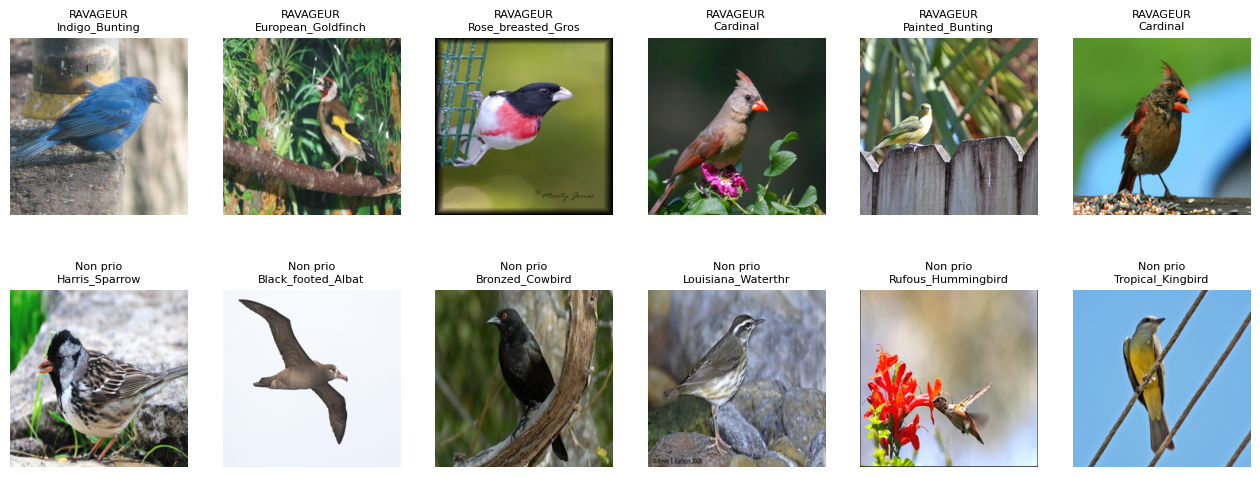

In [7]:
fig, ax = plt.subplots(2, 6, figsize=(16, 6))
for r, lab in enumerate([1, 0]):
    ids = np.where(y_tr == lab)[0][:6]
    for a, i in zip(ax[r], ids):
        a.imshow(X_tr[i]); a.axis("off"); a.set_title(("RAVAGEUR\n" if lab else "Non prio\n") + class_names[lab_tr[i]][:18], fontsize=8)
plt.show()

## 3. Modèle baseline (CNN from scratch)
Augmentation et normalisation sont **dans le modèle** (actives seulement à l'entraînement) : pas de pipeline tf.data fragile.

In [8]:
# 1. Pipeline d'augmentation de données pour limiter le surapprentissage (uniquement actif pendant le fit())
def augment():
    return tf.keras.Sequential([
        layers.RandomFlip("horizontal"),  # Retournement horizontal aléatoire
        layers.RandomRotation(0.1),       # Rotation de +/- 10%
        layers.RandomZoom(0.15),          # Zoom de +/- 15%
        layers.RandomContrast(0.2)        # Ajustement aléatoire du contraste
    ], name="augment")

# 2. Compilation standardisée d'un modèle avec métriques de classification robustes
def compile_model(m, lr):
    m.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",       # Perte adaptée à la classification binaire
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )
    return m

# 3. Définition de l'architecture de la Baseline CNN (from scratch)
def build_baseline():
    m = models.Sequential([
        layers.Input((IMG, IMG, 3)),
        augment(),                        # Couche d'augmentation
        layers.Rescaling(1/255)           # Normalisation des pixels [0, 255] -> [0, 1]
    ])
    # Bloc d'extraction de caractéristiques (Convolution -> Pooling -> Normalisation)
    for f in [32, 64, 128, 256]:
        m.add(layers.Conv2D(f, 3, padding="same", activation="relu"))
        m.add(layers.MaxPooling2D())
        m.add(layers.BatchNormalization())
    # Tête de classification
    m.add(layers.GlobalAveragePooling2D())
    m.add(layers.Dropout(0.4))            # Dropout pour éviter le surapprentissage
    m.add(layers.Dense(128, activation="relu"))
    m.add(layers.Dropout(0.3))
    m.add(layers.Dense(1, activation="sigmoid")) # Sigmoid pour obtenir une probabilité binaire
    return compile_model(m, 1e-3)

# 4. Calcul des poids des classes pour contrebalancer le déséquilibre (7.5% de ravageurs)
n0, n1 = (y_tr == 0).sum(), (y_tr == 1).sum()
class_weight = {0: len(y_tr)/(2*n0), 1: len(y_tr)/(2*n1)}
print("Poids attribués aux classes :", class_weight)

# 5. Définition des callbacks (EarlyStopping basé sur l'AUC de validation et réduction dynamique du LR)
cbs = lambda: [
    tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
]

# 6. Entraînement de la baseline
baseline = build_baseline()
h_base = baseline.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=15, batch_size=32,
                      class_weight=class_weight, callbacks=cbs())

Poids attribués aux classes : {0: np.float64(0.5405862457722661), 1: np.float64(6.659722222222222)}
Epoch 1/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 25s 91ms/step - accuracy: 0.5460 - auc: 0.5091 - loss: 0.8367 - precision: 0.0792 - recall: 0.4750 - val_accuracy: 0.0751 - val_auc: 0.5000 - val_loss: 1.0176 - val_precision: 0.0751 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 78ms/step - accuracy: 0.5616 - auc: 0.5490 - loss: 0.7515 - precision: 0.0840 - recall: 0.4889 - val_accuracy: 0.1001 - val_auc: 0.5717 - val_loss: 1.0141 - val_precision: 0.0770 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 79ms/step - accuracy: 0.5769 - auc: 0.5821 - loss: 0.7304 - precision: 0.1001 - recall: 0.5806 - val_accuracy: 0.6839 - val_auc: 0.5989 - val_loss: 0.6252 - val_precision: 0.1019 - val_recall: 0.4111 - learning_rate: 0.0010
Epoch 4/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 79ms/step - accuracy: 0.5885 - auc: 0.6147 - loss: 0

## 4. Transfert learning : MobileNetV2
Phase 1 : base gelée. Phase 2 : fine-tuning léger des 30 dernières couches (lr faible).

In [9]:
# 1. Construction du modèle MobileNetV2 pour le Transfer Learning
def build_mobilenet():
    # Chargement de la base MobileNetV2 pré-entraînée sur ImageNet sans la couche finale
    base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
    base.trainable = False  # Verrouillage initial de la base pré-entraînée

    inp = layers.Input((IMG, IMG, 3))
    x = augment()(inp)      # Augmentation
    x = layers.Rescaling(1/127.5, offset=-1)(x) # Normalisation requise par MobileNetV2 [-1, 1]
    x = base(x, training=False)                 # Inférence de base (sans calcul des gradients du modèle principal)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x) # Couche de prédiction binaire spécifique
    return compile_model(models.Model(inp, out, name="MobileNetV2_ravageur"), 1e-3), base

mobilenet, base = build_mobilenet()

# Phase 1 : Entraînement uniquement de la nouvelle tête de classification
h1 = mobilenet.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=10, batch_size=32, class_weight=class_weight, callbacks=cbs())

# Phase 2 : Déverrouillage des 30 dernières couches de la base pour affiner l'apprentissage (Fine-tuning)
base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False

# Recompilation avec un taux d'apprentissage très faible pour ne pas corrompre les poids pré-entraînés
compile_model(mobilenet, 1e-5)
h2 = mobilenet.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=8, batch_size=32,
                   class_weight=class_weight, callbacks=cbs())

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 19s 87ms/step - accuracy: 0.6647 - auc: 0.7362 - loss: 0.6081 - precision: 0.1401 - recall: 0.6750 - val_accuracy: 0.7923 - val_auc: 0.8900 - val_loss: 0.4605 - val_precision: 0.2460 - val_recall: 0.8556 - learning_rate: 0.0010
Epoch 2/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.7587 - auc: 0.8517 - loss: 0.4822 - precision: 0.2076 - recall: 0.7861 - val_accuracy: 0.8140 - val_auc: 0.9072 - val_loss: 0.4452 - val_precision: 0.2715 - val_recall: 0.8778 - learning_rate: 0.0010
Epoch 3/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.7856 - auc: 0.8647 - loss: 0.4626 - precision: 0.2315 - recall: 0.8000 - val_accuracy: 0.7381 - val_auc: 0.9169 - val_loss: 0.5567 - val_precision: 0.2157 - val_recall: 0.9444 - learning_rate: 0.0010
Epoch 4/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.8006 - auc: 0.8892 - loss: 0.4208 - precision: 0.2513 - recall: 0.8361 - val_ac

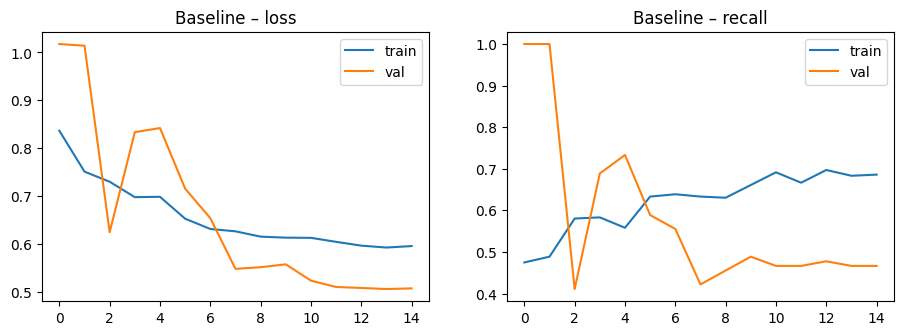

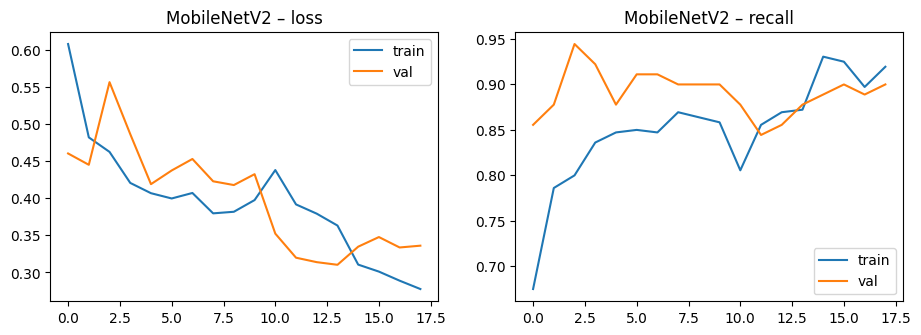

In [10]:
def curves(hs, title):
    h = {k: sum([x.history[k] for x in hs], []) for k in ["loss","val_loss","recall","val_recall"]}
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title(title+" – loss"); ax[0].legend()
    ax[1].plot(h["recall"], label="train"); ax[1].plot(h["val_recall"], label="val"); ax[1].set_title(title+" – recall"); ax[1].legend()
    plt.show()
curves([h_base], "Baseline"); curves([h1, h2], "MobileNetV2")

## 5. Évaluation sur le test
Le **recall ravageur** est prioritaire. Le seuil de décision est choisi **sur la validation** (jamais sur le test) : meilleure précision avec recall ≥ 90 %.

=== Baseline CNN | seuil=0.25 ===
                 precision    recall  f1-score   support

Non prioritaire      0.963     0.335     0.497      5357
       Ravageur      0.094     0.842     0.169       437

       accuracy                          0.373      5794
      macro avg      0.528     0.589     0.333      5794
   weighted avg      0.897     0.373     0.472      5794



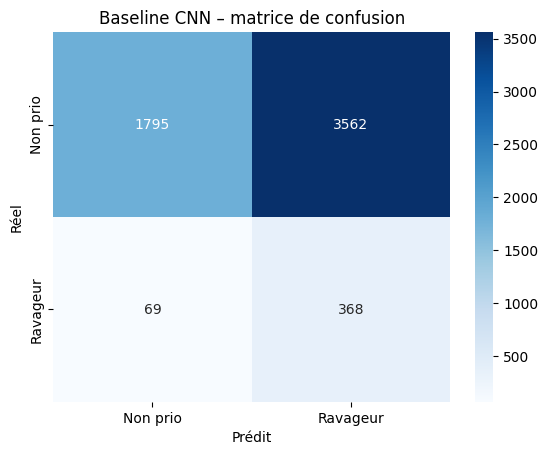

=== MobileNetV2 | seuil=0.53 ===
                 precision    recall  f1-score   support

Non prioritaire      0.987     0.858     0.918      5357
       Ravageur      0.332     0.865     0.480       437

       accuracy                          0.858      5794
      macro avg      0.660     0.861     0.699      5794
   weighted avg      0.938     0.858     0.885      5794



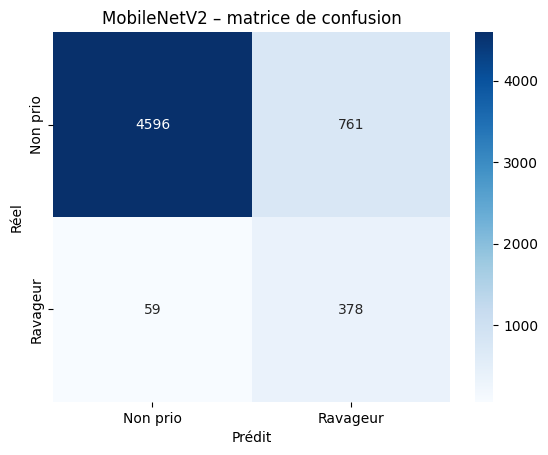

,Seuil,Accuracy,Precision,Recall,F1,AUC,Taux_FN,ms_par_image
Modèle,,,,,,,,
Baseline CNN,0.25,0.373,0.094,0.842,0.169,0.704,0.158,0.995
MobileNetV2,0.53,0.858,0.332,0.865,0.480,0.935,0.135,1.888


In [11]:
# 1. Détermination du meilleur seuil de décision pour assurer un taux de Rappel (Recall) minimal
def best_threshold(y, p, min_recall=0.90):
    pr, rc, th = precision_recall_curve(y, p)
    # Sélection des seuils garantissant un recall >= 90%
    ok = np.where(rc[:-1] >= min_recall)[0]
    # On choisit parmi eux celui qui maximise la précision
    return float(th[ok[np.argmax(pr[:-1][ok])]]) if len(ok) else 0.5

# 2. Évaluation complète du modèle sur l'ensemble de test
def evaluate(model, name):
    # Calcul du seuil optimal de manière stricte sur le jeu de validation uniquement
    p_val = model.predict(X_val, batch_size=64, verbose=0).ravel()
    thr = best_threshold(y_val, p_val)

    # Inférence sur le jeu de test et mesure du temps de réponse moyen
    t = time.time()
    p = model.predict(X_te, batch_size=64, verbose=0).ravel()
    ms = (time.time()-t)/len(X_te)*1000

    # Application du seuil optimal pour obtenir la décision finale binaire
    pred = (p >= thr).astype(int)
    cm = confusion_matrix(y_te, pred)
    fn_rate = cm[1,0]/cm[1].sum() # Taux de faux négatifs

    # Affichage du rapport de classification
    print(f"=== {name} | seuil={thr:.2f} ===")
    print(classification_report(y_te, pred, target_names=["Non prioritaire","Ravageur"], digits=3))

    # Affichage de la matrice de confusion
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Non prio","Ravageur"], yticklabels=["Non prio","Ravageur"])
    plt.title(f"{name} – matrice de confusion"); plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.show()

    return dict(Modèle=name, Seuil=round(thr,2), Accuracy=(pred==y_te).mean(), Precision=precision_score(y_te,pred),
                Recall=recall_score(y_te,pred), F1=f1_score(y_te,pred), AUC=roc_auc_score(y_te,p),
                Taux_FN=fn_rate, ms_par_image=ms), p, pred, thr

# Lancement de l'évaluation sur les deux modèles
r_b, p_b, pred_b, thr_b = evaluate(baseline, "Baseline CNN")
r_m, p_m, pred_m, thr_m = evaluate(mobilenet, "MobileNetV2")
pd.DataFrame([r_b, r_m]).round(3).set_index("Modèle")

## 6. Analyse des erreurs (faux négatifs)

59 faux négatifs sur 437 ravageurs

Taux de faux négatifs par espèce ravageur :
espèce
Gray_crowned_Rosy_Finch    0.41
Rusty_Blackbird            0.40
Brewer_Blackbird           0.21
Rose_breasted_Grosbeak     0.17
Bobolink                   0.17
Painted_Bunting            0.14
Lazuli_Bunting             0.11
European_Goldfinch         0.10
Cardinal                   0.07
Red_winged_Blackbird       0.07
Purple_Finch               0.07
Yellow_headed_Blackbird    0.04
Blue_Grosbeak              0.03
American_Goldfinch         0.03
Indigo_Bunting             0.00

Espèces non-ravageurs les plus confondues (faux positifs) :
Scarlet_Tanager         30
Vermilion_Flycatcher    29
Cape_Glossy_Starling    28
Summer_Tanager          28
Bronzed_Cowbird         27
Evening_Grosbeak        26
Boat_tailed_Grackle     25
Pine_Grosbeak           24


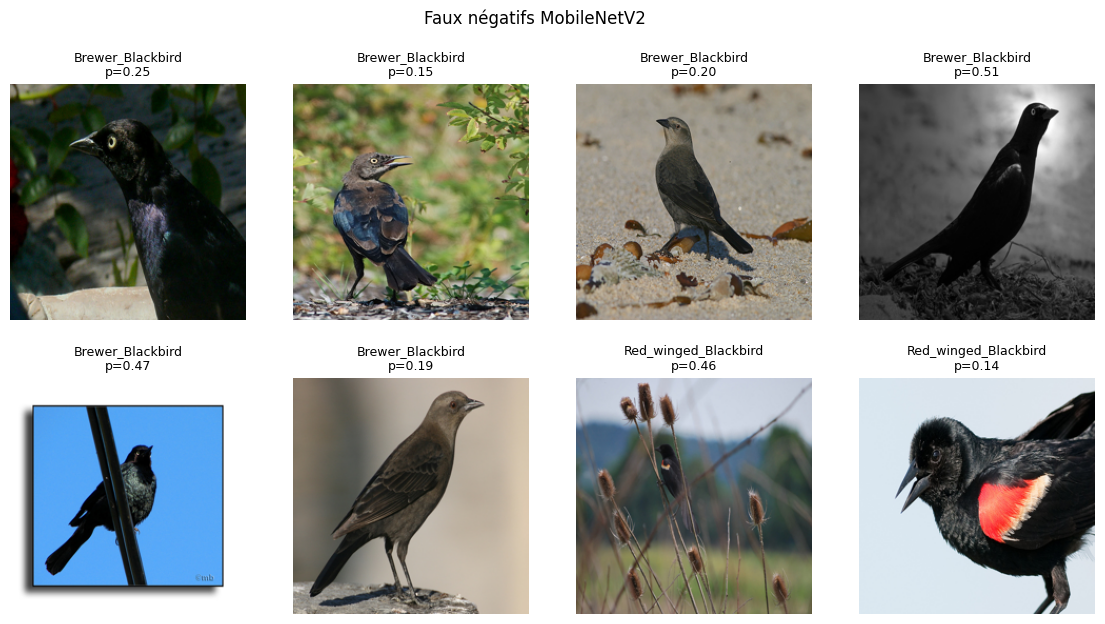

In [12]:
fn = np.where((y_te == 1) & (pred_m == 0))[0]
print(f"{len(fn)} faux négatifs sur {int(y_te.sum())} ravageurs")
rec = pd.DataFrame({"espèce": [class_names[l] for l in lab_te[y_te==1]], "manqué": (pred_m[y_te==1]==0)})
print("\nTaux de faux négatifs par espèce ravageur :")
print(rec.groupby("espèce")["manqué"].mean().sort_values(ascending=False).round(2).to_string())
fp = np.where((y_te == 0) & (pred_m == 1))[0]
print("\nEspèces non-ravageurs les plus confondues (faux positifs) :")
print(pd.Series([class_names[l] for l in lab_te[fp]]).value_counts().head(8).to_string())
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for a, i in zip(ax.ravel(), fn[:8]):
    a.imshow(X_te[i]); a.axis("off"); a.set_title(f"{class_names[lab_te[i]][:20]}\np={p_m[i]:.2f}", fontsize=9)
plt.suptitle("Faux négatifs MobileNetV2"); plt.show()

## 7. Sauvegarde et démonstration Gradio

In [14]:
mobilenet.save("bird_pest_mobilenetv2.keras")
json.dump({"threshold": thr_m}, open("config.json", "w"))
import gradio as gr
def predict(img):
    x = np.asarray(img.convert("RGB").resize((IMG, IMG)), dtype="float32")[None]
    p = float(mobilenet.predict(x, verbose=0)[0, 0])
    alert = "ALERTE : ravageur potentiel (validation humaine requise)" if p >= thr_m else "Non prioritaire"
    return {"Ravageur potentiel": p, "Non prioritaire": 1-p}, alert
gr.Interface(predict, gr.Image(type="pil", label="Image d'oiseau"),
             [gr.Label(label="Confiance"), gr.Textbox(label="Message")],
             title="Détection d'oiseaux ravageurs du riz").launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://10b678941377422c07.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 8. Limites, biais et éthique
- **Domaine** : CUB = oiseaux nord-américains, photos de qualité ; les classes « ravageur » sont des proxys, pas les Queleas/Dendrocygnes locaux → performance réelle sur le terrain probablement plus faible.
- **Déséquilibre** (~7,5 % de ravageurs) : géré par `class_weight` et par un seuil ajusté pour le recall.
- **Faux négatifs** = attaques non signalées ; **faux positifs** = fatigue d'alerte. Validation humaine obligatoire avant toute action.
- Aucune méthode de lutte nuisible à l'environnement ne doit être encouragée (effarouchement non létal uniquement).
- **Pistes** : photos locales annotées (parcelles du fleuve Sénégal, sans personnes ni données sensibles) pour fine-tuning/test ; détection d'objets (YOLO) pour les volées ; modèle TFLite sur caméra/IoT ; enrichissement via iNaturalist/GBIF/Xeno-canto (images/ressources ouvertes).